In [ ]:
# Sources:
# 1. How does logical regression work in python: https://www.youtube.com/watch?v=aL21Y-u0SRs
# 2. ROC-curve: https://medium.com/%40anixlynch/11-visuals-to-evaluate-machine-learning-models-232498edc636


In [25]:
# Import statements
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression

# For model evaluation
from sklearn.metrics import roc_auc_score
from sklearn.metrics import balanced_accuracy_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import brier_score_loss
from sklearn.calibration import calibration_curve

In [13]:
# Reading and preparing data and tools
FILE_IN = "./data_prepared.csv"
SAMPLE_SIZE = 100000

# Read prepared data into a pd dataframe
df_data = pd.read_csv(FILE_IN)

# Change Susceptible = 1, Resistible = 0
df_data = df_data.replace({"susceptibility": {"Susceptible": 1, "Resistant": 0}})

In [ ]:
# Preparing the dataset for the model

# Mi computer weak, mi computer cannot take big big data
df_sample = df_data.sample(SAMPLE_SIZE)

# Drop identifier columns
df_sample = df_sample.drop(['anon_id', 'pat_enc_csn_id_coded', 'order_proc_id_coded', 'order_time_jittered_utc'], axis=1)

# Turn the data to a table with only numerical values
data = pd.get_dummies(df_sample, drop_first=True, dtype=int)
data = data.rename(columns={'susceptibility_1': 'susceptibility'})

# Test and train data split
X_train, X_test, y_train, y_test = train_test_split(data.drop('susceptibility', axis=1), data['susceptibility'], train_size=0.8, random_state=11)

print(X_train.shape, X_test.shape)
print(y_train.shape, y_test.shape)

(80000, 246) (20000, 246)
(80000,) (20000,)


In [15]:
# Train the model
model_logreg = LogisticRegression(max_iter=5000) # The same max iteration count as for the other model
model_logreg.fit(X_train, y_train) # Show the output as the model is being trained)


c:\Users\Emma\Documents\Koodeja\Data Intelligence\sklearn-env\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 5000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=5000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",5000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

In [18]:
# Validating the results WITH Data used in testing

# Testing the model with data new to it
y_pred = model_logreg.predict(X_test)

# ROC-AUC: Compute Area Under the Receiver Operating Characteristic Curve (ROC AUC) from prediction scores.
print("ROC-AUC: {:.4f}".format(roc_auc_score(y_test, y_pred)))

# Balanced accuracy: The balanced accuracy in binary and multiclass classification problems to deal with imbalanced datasets. It is defined as the average of recall obtained on each class.
print("Balanced accuracy: {:.4f}".format(balanced_accuracy_score(y_test, y_pred)))

# Precision score: The precision is the ratio tp / (tp + fp) where tp is the number of true positives and fp the number of false positives. The precision is intuitively the ability of the classifier not to label as positive a sample that is negative.
# The best value is 1 and the worst value is 0.
print("Precision score: {:.4f}".format(precision_score(y_test, y_pred)))

# Recall score: The recall is the ratio tp / (tp + fn) where tp is the number of true positives and fn the number of false negatives. The recall is intuitively the ability of the classifier to find all the positive samples.
# The best value is 1 and the worst value is 0.
print("Recall score: {:.4f}".format(recall_score(y_test, y_pred)))

# brier score loss: The Brier score measures the mean squared difference between the predicted probability and the actual outcome. 
# The smaller the Brier score loss, the better, hence the naming with “loss”.
print("Brier score loss: {:.4f}".format(brier_score_loss(y_test, y_pred)))

ROC-AUC: 0.6193
Balanced accuracy: 0.6193
Precision score: 0.8289
Recall score: 0.9552
Brier score loss: 0.1898


Text(0, 0.5, 'True Probability')

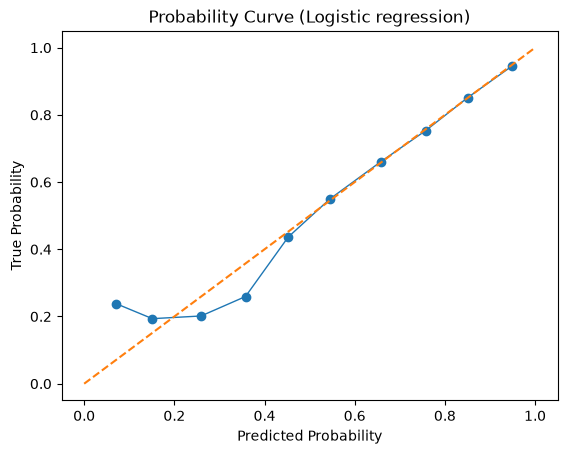

In [30]:
# Calibration curve

prob_pos = model_logreg.predict_proba(X_test)[:, 1]
true_pos, pred_pos = calibration_curve(y_test, prob_pos, n_bins=10)

plt.plot(pred_pos, true_pos, marker='o', linewidth=1, label='Logistic Regression')
plt.plot([0, 1], [0, 1], linestyle='--')

plt.title('Probability Curve (Logistic regression)')
plt.xlabel('Predicted Probability')
plt.ylabel('True Probability')

# How to interpret the plot:
# X-axis: Model’s predicted probabilities
# Y-axis: Actually observed frequencies
# Gray dashed line: Perfect calibration (predicted = observed)
# Blue line: Model’s calibration curve